Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-tenzory-vektorno-matrichnye-operacii

In [1]:
import torch

In [8]:
a = torch.arange(9).view(3, -1)
b = torch.arange(9).view(3, -1)
a

tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]])

In [10]:
# поэлементное умножение
a.mul(b)

tensor([[ 0,  1,  4],
        [ 9, 16, 25],
        [36, 49, 64]])

In [11]:
# матричное умножение. или короче a@b
a.matmul(b)

tensor([[ 15,  18,  21],
        [ 42,  54,  66],
        [ 69,  90, 111]])

In [14]:
# то же самое, но без транслирования
a.mm(b)

tensor([[ 15,  18,  21],
        [ 42,  54,  66],
        [ 69,  90, 111]])

In [15]:
a = torch.arange(9).view(3, -1)
b = torch.arange(3).view(3, -1)

In [16]:
a.matmul(b)

tensor([[ 5],
        [14],
        [23]])

In [18]:
b.mm(a)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (3x1 and 3x3)

Следующий меод применяется для перемножения сразу нескольких матриц - батчей

In [20]:
bx = torch.randn(7,3,5)
by = torch.randn(7,5,4)

bc = torch.bmm(bx, by)
bc.shape

torch.Size([7, 3, 4])

Помним, что перемножение векторов бывает матричное и скалярное (отличаются по тому, что получается в итоге -матрциа или скаляр)

In [21]:
a = torch.rand(5)

tensor([0.9186, 0.2992, 0.8278, 0.5260, 0.8411])

In [24]:
# матричное (оно еще называется внешнее)
torch.outer(a, a)

tensor([[0.8439, 0.2749, 0.7604, 0.4832, 0.7727],
        [0.2749, 0.0895, 0.2477, 0.1574, 0.2517],
        [0.7604, 0.2477, 0.6852, 0.4354, 0.6963],
        [0.4832, 0.1574, 0.4354, 0.2767, 0.4424],
        [0.7727, 0.2517, 0.6963, 0.4424, 0.7075]])

In [22]:
# скалярное
a.dot(a)

tensor(2.6029)

Умножение вектора на матрицу

In [39]:
a = torch.arange(12).view(3, -1) # dim=3x4
b = torch.arange(4) # dim=3


In [41]:
# Mатрица на Vектор
# [3x4]*[3] == [3x4]*[3x1] = [3x1]
torch.mv(a, b)

tensor([14, 38, 62])

In [42]:
a.mv(b)

tensor([14, 38, 62])

решение СЛАУ  
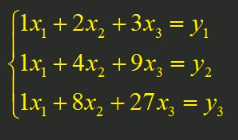

In [55]:
a = torch.tensor([1,2,3,1,4,9,1,8,27]).view(3, -1).float()
a

tensor([[ 1.,  2.,  3.],
        [ 1.,  4.,  9.],
        [ 1.,  8., 27.]])

In [56]:
# вычслим ранг. Если равен размеру матрицы, значит линейныхкомбинаций нет
torch.linalg.matrix_rank(a)

tensor(3)

In [57]:
# определим вектор таргетов

In [61]:
y = torch.tensor([10, 20, 30], dtype=torch.float32)

In [63]:
roots = torch.linalg.solve(a, y)
roots

tensor([-5.0000, 10.0000, -1.6667])

In [65]:
# проверяем
a.mv(roots)

tensor([10.0000, 20.0000, 30.0000])

есть еще одно решение - через обратную матрицу  
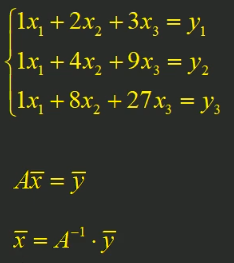

In [66]:
inv_a = torch.linalg.inv(a)
inv_a

tensor([[ 3.0000, -2.5000,  0.5000],
        [-1.5000,  2.0000, -0.5000],
        [ 0.3333, -0.5000,  0.1667]])

In [68]:
roots = inv_a.mv(y)
roots

tensor([-5.0000, 10.0000, -1.6667])

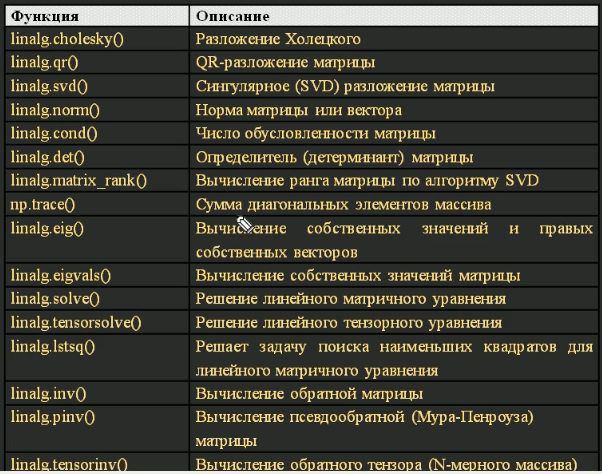

In [77]:
import torch

x = torch.rand(2, 7)
y = torch.rand(7)

torch.mv(x, y)

tensor([2.5846, 2.6315])

In [79]:
torch.mm(x, y)

RuntimeError: mat2 must be a matrix